# XGBoost: feature engineering και Optuna
Σε αυτό το notebook δοκιμάζουμε αν νέες μεταβλητές και ρύθμιση υπερπαραμέτρων βελτιώνουν το XGBoost.


In [1]:
import json
import numpy as np
import pandas as pd
import optuna
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score

#### 1) Δεδομένα και ίδιος διαχωρισμός με το Notebook 1
Ιδιος διαχωρισμός train/test (ανά χρήστη, random_state=42), ώστε τα αποτελέσματα να συγκρίνονται με το Notebook 1.

In [2]:
SEED = 42
df = pd.read_csv('customer_model.csv')

drop_cols = ['target_event', 'target_actual_profit', 'target_revenue',
             'target_customer_value', 'target_customer_value_lag1',
             'row_id', 'user_id', 'time_step']

y = df['target_event']
groups = df['user_id']
X = df.drop(columns=drop_cols)
X = X.drop(columns=[c for c in X.columns if X[c].nunique() == 1])

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(sgkf.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (90087, 265) | Test: (22523, 265)


#### 2)  51 χαρακτηριστικά του Notebook 1 και λόγος κλάσεων (non-churn προς churn)

In [3]:
final_cols = json.load(open('final_cols.json'))
print(len(final_cols), 'χαρακτηριστικά')

ratio = (y_train == 0).sum() / (y_train == 1).sum()
print('Λόγος κλάσεων:', round(ratio, 3))

51 χαρακτηριστικά
Λόγος κλάσεων: 2.117


#### 3) Baseline: σημείο αναφοράς
Μετράω το XGBoost του Notebook 1 με cross-validation στο train. Το ROC-AUC = 0,899 είναι ο αριθμός που πρέπει να ξεπεράσουν οι νέες μεταβλητές.

In [4]:
baseline_params = {'n_estimators': 376, 'learning_rate': 0.010026522473407051,
                   'max_depth': 6, 'subsample': 0.8469926038510867,
                   'colsample_bytree': 0.9692763545078751}

def make_model(params):
    return XGBClassifier(**params, scale_pos_weight=ratio, eval_metric='logloss',
                         random_state=SEED, n_jobs=-1)

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

def cv_auc(params, data, cols):
    return cross_val_score(make_model(params), data[cols], y_train,
                           groups=groups_train, cv=cv, scoring='roc_auc')

base_scores = cv_auc(baseline_params, X_train, final_cols)
print('ROC-AUC ανά fold:', base_scores.round(4))
print('Μέσος όρος:', round(base_scores.mean(), 4))

ROC-AUC ανά fold: [0.8953 0.8937 0.9015 0.9054 0.8991]
Μέσος όρος: 0.899


#### 4) Feature engineering

##### 4.1) ομάδα 1, funnel

Παίρνω αναλογίες από υπάρχουσες στήλες: view_to_cart, cart_to_purchase, view_to_purchase (πόσο συχνά οι προβολές γίνονται καλάθι και αγορά)
Δοκιμάζω αν η προσθήκη τους βελτιώνει το CV ROC-AUC σε σχέση με το baseline.

In [5]:
needed = ['view_count_sum', 'cart_count_sum', 'purchase_count_sum']
for c in needed:
    print(c, '->', 'υπάρχει' if c in X_train.columns else 'ΛΕΙΠΕΙ')

view_count_sum -> υπάρχει
cart_count_sum -> υπάρχει
purchase_count_sum -> υπάρχει


In [6]:
def safe_div(a, b):
    return a / (b.clip(lower=0) + 1)

def funnel_features(d):
    new = pd.DataFrame(index=d.index)
    new['view_to_cart']     = safe_div(d['cart_count_sum'],     d['view_count_sum'])
    new['cart_to_purchase'] = safe_div(d['purchase_count_sum'], d['cart_count_sum'])
    new['view_to_purchase'] = safe_div(d['purchase_count_sum'], d['view_count_sum'])
    return new

funnel_train = funnel_features(X_train)
print(funnel_train.describe().T[['mean', 'min', 'max']].round(3))

                   mean    min    max
view_to_cart      0.250  0.000  10.25
cart_to_purchase  0.970  0.019  71.00
view_to_purchase  0.192  0.001   7.50


In [7]:
X_train_f = pd.concat([X_train, funnel_train], axis=1)
funnel_cols = list(funnel_train.columns)

scores = cv_auc(baseline_params, X_train_f, final_cols + funnel_cols)
print('ROC-AUC ανά fold:', scores.round(4))
print('Μέσος όρος:', round(scores.mean(), 4))
print('Baseline:      ', round(base_scores.mean(), 4))
print('Διαφορά:       ', round(scores.mean() - base_scores.mean(), 4))

ROC-AUC ανά fold: [0.8953 0.8936 0.9015 0.9054 0.8991]
Μέσος όρος: 0.899
Baseline:       0.899
Διαφορά:        -0.0


**Συμπέρασμα (ομάδα 1, funnel):** CV ROC-AUC 0,899 έναντι 0,899 του baseline
Οι αναλογίες προβολής-καλαθιού-αγοράς δεν βελτιώνουν το μοντέλο μάλλον γιατί η πληροφορία υπάρχει ήδη στα 51 χαρακτηριστικά. Η ομάδα δεν συμπεριλαμβάνεται.

##### 4.2) ομάδα 2, recency και ρυθμός

Συγκρίνω τον χρόνο από την τελευταία αγορά/επίσκεψη με τον συνηθισμένο ρυθμό του κάθε πελάτη (π.χ. «έχει καθυστερήσει 3 φορές περισσότερο από όσο συνήθως»).


In [8]:
needed = ['purchase_recency_min', 'purchase_recency_max', 'session_recency_min',
          'inter_purchase_time_mean', 'inter_session_time_mean']
for c in needed:
    print(c, '->', 'υπάρχει' if c in X_train.columns else 'ΛΕΙΠΕΙ')

purchase_recency_min -> υπάρχει
purchase_recency_max -> υπάρχει
session_recency_min -> υπάρχει
inter_purchase_time_mean -> υπάρχει
inter_session_time_mean -> υπάρχει


In [9]:
def recency_features(d):
    new = pd.DataFrame(index=d.index)
    new['purchase_recency_range'] = d['purchase_recency_max'] - d['purchase_recency_min']
    new['session_minus_purchase_recency'] = d['session_recency_min'] - d['purchase_recency_min']
    new['purchase_overdue_ratio'] = safe_div(d['purchase_recency_min'], d['inter_purchase_time_mean'])
    new['session_overdue_ratio'] = safe_div(d['session_recency_min'], d['inter_session_time_mean'])
    return new

recency_train = recency_features(X_train)
print(recency_train.describe().T[['mean', 'min', 'max']].round(3))

                                  mean      min      max
purchase_recency_range          60.869    0.000  179.589
session_minus_purchase_recency  -4.534 -158.357    0.001
purchase_overdue_ratio           5.923    0.000  157.195
session_overdue_ratio            6.171    0.000  156.515


In [10]:
X_train_r = pd.concat([X_train, recency_train], axis=1)
recency_cols = list(recency_train.columns)

scores_r = cv_auc(baseline_params, X_train_r, final_cols + recency_cols)
print('ROC-AUC ανά fold:', scores_r.round(4))
print('Μέσος όρος:', round(scores_r.mean(), 4))
print('Baseline:  ', round(base_scores.mean(), 4))
print('Διαφορά:   ', round(scores_r.mean() - base_scores.mean(), 5))

ROC-AUC ανά fold: [0.8992 0.8977 0.9047 0.9094 0.9021]
Μέσος όρος: 0.9026
Baseline:   0.899
Διαφορά:    0.00363


**Συμπέρασμα (ομάδα 2, recency και ρυθμός):** CV ROC-AUC 0,9026 έναντι 0,8990 του baseline.
Η βελτίωση εμφανίζεται και στα 5 folds, άρα είναι συνεπής. Η ομάδα συμπεριλαμβάνεται.

##### 4.3) ομάδα 3, τάση (trend)
Συγκρίνω τη δραστηριότητα του τρέχοντος μήνα με τον κινητό μέσο των 3 μηνών (αγορές, επισκέψεις, έσοδα). Αρνητική τιμή σημαίνει ότι η δραστηριότητα πέφτει.


In [11]:
needed = ['purchase_count_month_lag0', 'purchase_count_month_ma3',
          'session_count_month_lag0', 'session_count_month_ma3',
          'purchase_revenue_month_lag0', 'purchase_revenue_month_ma3']
for c in needed:
    print(c, '->', 'υπάρχει' if c in X_train.columns else 'ΛΕΙΠΕΙ')

purchase_count_month_lag0 -> υπάρχει
purchase_count_month_ma3 -> υπάρχει
session_count_month_lag0 -> υπάρχει
session_count_month_ma3 -> υπάρχει
purchase_revenue_month_lag0 -> υπάρχει
purchase_revenue_month_ma3 -> υπάρχει


In [12]:
def trend_features(d):
    new = pd.DataFrame(index=d.index)
    new['purchase_count_trend']   = d['purchase_count_month_lag0']   - d['purchase_count_month_ma3']
    new['session_count_trend']    = d['session_count_month_lag0']    - d['session_count_month_ma3']
    new['purchase_revenue_trend'] = d['purchase_revenue_month_lag0'] - d['purchase_revenue_month_ma3']
    return new

trend_train = trend_features(X_train)
print(trend_train.describe().T[['mean', 'min', 'max']].round(3))

                           mean        min        max
purchase_count_trend     -0.663     -78.00     49.500
session_count_trend      -1.307    -581.00    408.750
purchase_revenue_trend -399.297 -171518.01  83720.282


In [13]:
X_train_t = pd.concat([X_train, trend_train], axis=1)
trend_cols = list(trend_train.columns)

scores_t = cv_auc(baseline_params, X_train_t, final_cols + trend_cols)
print('ROC-AUC ανά fold:', scores_t.round(4))
print('Μέσος όρος:', round(scores_t.mean(), 4))
print('Baseline:  ', round(base_scores.mean(), 4))
print('Διαφορά:   ', round(scores_t.mean() - base_scores.mean(), 5))

ROC-AUC ανά fold: [0.8969 0.8955 0.9028 0.9072 0.9003]
Μέσος όρος: 0.9005
Baseline:   0.899
Διαφορά:    0.00155


**Συμπέρασμα (ομάδα 3, τάση):** CV ROC-AUC 0,9005 έναντι 0,8990 του baseline. 
Η βελτίωση είναι μικρή αλλά θετική και στα 5 folds. Θεωρείται οριακή και θα ελεγχθεί σε συνδυασμό με την ομάδα recency.

#### 4.4) Συνδυασμός ομάδων
συνδυάζω τις ομάδες μαζί, για να δω αν τα κέρδη αθροίζονται ή αν οι ομάδες πληροφορούν το ίδιο πράγμα.

In [14]:
X_train_all = pd.concat([X_train, funnel_train, recency_train, trend_train], axis=1)

combos = {
    'B: 51 + recency':                  final_cols + recency_cols,
    'C: 51 + recency + τάση':           final_cols + recency_cols + trend_cols,
    'D: 51 + recency + τάση + funnel':  final_cols + recency_cols + trend_cols + funnel_cols,
}

rows = [{'Σύνολο': 'A: 51 (baseline)', 'Αριθμός': len(final_cols),
         'CV ROC-AUC': round(base_scores.mean(), 5), 'Διαφορά από A': 0.0}]
for name, cols in combos.items():
    s = cv_auc(baseline_params, X_train_all, cols)
    rows.append({'Σύνολο': name, 'Αριθμός': len(cols),
                 'CV ROC-AUC': round(s.mean(), 5),
                 'Διαφορά από A': round(s.mean() - base_scores.mean(), 5)})

pd.DataFrame(rows).set_index('Σύνολο')

,Αριθμός,CV ROC-AUC,Διαφορά από A
Σύνολο,,,
A: 51 (baseline),51,0.89898,0.00000
B: 51 + recency,55,0.90261,0.00363
C: 51 + recency + τάση,58,0.90277,0.00379
D: 51 + recency + τάση + funnel,61,0.90274,0.00376


**Συμπέρασμα (συνδυασμοί):** Το σύνολο  Β: 51 + recency δίνει CV ROC-AUC 0,9026 έναντι 0,8990 του baseline.
Η προσθήκη της τάσης και του funnel δεν βελτιώνει περαιτέρω, άρα τα κέρδη δεν αθροίζονται. Επιλέγεται το απλούστερο σύνολο B, με τις 4 μεταβλητές recency. Ναι μεν το Γ είχε οριακά υψηλότερο μέσο CV ROC-AUC (+0,0002), αλλά η διαφορά Γ − Β ανά fold δεν είναι σταθερή (από −0,00001 έως +0,0004), σε αντίθεση με το κέρδος του Β από το baseline (+0,003 έως +0,004 σε κάθε fold). Επελέχθη το Β ως το απλούστερο σύνολο με πρακτικά ίδια απόδοση.

In [15]:
scores_A = base_scores   # baseline: 51 χαρακτηριστικά (από το κελί 4)
scores_B = cv_auc(baseline_params, X_train_all, final_cols + recency_cols)
scores_C = cv_auc(baseline_params, X_train_all, final_cols + recency_cols + trend_cols)

print('Α (baseline) ανά fold:', scores_A.round(5), '| μέσος:', round(scores_A.mean(), 5))
print('Β ανά fold:           ', scores_B.round(5), '| μέσος:', round(scores_B.mean(), 5))
print('Γ ανά fold:           ', scores_C.round(5), '| μέσος:', round(scores_C.mean(), 5))
print()
print('Β − Α ανά fold:', (scores_B - scores_A).round(5), '| μέσος:', round((scores_B - scores_A).mean(), 5))
print('Γ − Β ανά fold:', (scores_C - scores_B).round(5), '| μέσος:', round((scores_C - scores_B).mean(), 5))

Α (baseline) ανά fold: [0.89526 0.89367 0.90155 0.90537 0.89907] | μέσος: 0.89898
Β ανά fold:            [0.89923 0.89767 0.90467 0.9094  0.9021 ] | μέσος: 0.90261
Γ ανά fold:            [0.89922 0.89786 0.90503 0.90962 0.90213] | μέσος: 0.90277

Β − Α ανά fold: [0.00396 0.004   0.00312 0.00403 0.00303] | μέσος: 0.00363
Γ − Β ανά fold: [-1.0e-05  1.9e-04  3.7e-04  2.2e-04  2.0e-05] | μέσος: 0.00016


#### 5) Ρύθμιση υπερπαραμέτρων με Optuna
Χρησιμοποιώ το σύνολο B (51 + recency, 55 χαρακτηριστικά). Το Optuna δοκιμάζει διαδοχικά συνδυασμούς υπερπαραμέτρων και μαθαίνει από τις προηγούμενες δοκιμές. Κάθε δοκιμή αξιολογείται με το ίδιο CV στο train.
Η πρώτη δοκιμή είναι οι παράμετροι του baseline, ώστε το αποτέλεσμα να μην μπορεί να βγει χειρότερο από το 0,9026.

In [16]:

optuna.logging.set_verbosity(optuna.logging.WARNING)

use_cols = final_cols + recency_cols      # σύνολο B (55 χαρακτηριστικά)
N_TRIALS = 40              
print(len(use_cols), 'χαρακτηριστικά')

55 χαρακτηριστικά


In [17]:
def objective(trial):
    params = {
        'n_estimators':     trial.suggest_int('n_estimators', 100, 600),
        'learning_rate':    trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'max_depth':        trial.suggest_int('max_depth', 3, 10),
        'subsample':        trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 20),
        'gamma':            trial.suggest_float('gamma', 0.0, 10.0),
        'reg_lambda':       trial.suggest_float('reg_lambda', 1e-2, 10.0, log=True),
        'reg_alpha':        trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
    }
    return cv_auc(params, X_train_r, use_cols).mean()

study = optuna.create_study(direction='maximize',
                            sampler=optuna.samplers.TPESampler(seed=SEED))

# Πρώτη δοκιμή: οι παράμετροι του baseline
study.enqueue_trial({**baseline_params, 'min_child_weight': 1, 'gamma': 0.0,
                     'reg_lambda': 1.0, 'reg_alpha': 1e-3})

study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

print('Καλύτερο CV ROC-AUC:', round(study.best_value, 5))
print('Baseline (σύνολο B): ', round(scores_r.mean(), 5))
print('Καλύτερες παράμετροι:')
for k, v in study.best_params.items():
    print(f'  {k}: {v}')

  0%|          | 0/40 [00:00<?, ?it/s]

Καλύτερο CV ROC-AUC: 0.90346
Baseline (σύνολο B):  0.90261
Καλύτερες παράμετροι:
  n_estimators: 552
  learning_rate: 0.01704445981930769
  max_depth: 7
  subsample: 0.7552610930341807
  colsample_bytree: 0.6849947689296318
  min_child_weight: 15
  gamma: 7.47466264267038
  reg_lambda: 1.1554794319095754
  reg_alpha: 4.066117807804723


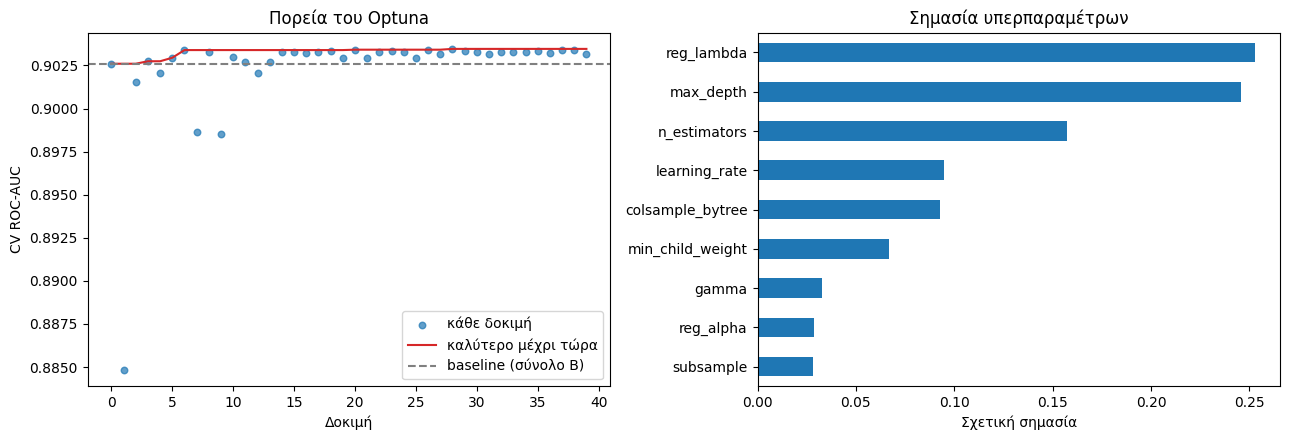

In [18]:
import matplotlib.pyplot as plt

trials = study.trials_dataframe()
trials['best_so_far'] = trials['value'].cummax()
trials.to_csv('optuna_trials.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Αριστερά: πορεία της αναζήτησης
ax[0].scatter(trials['number'], trials['value'], s=22, alpha=0.7, label='κάθε δοκιμή')
ax[0].plot(trials['number'], trials['best_so_far'], color='tab:red', label='καλύτερο μέχρι τώρα')
ax[0].axhline(scores_r.mean(), color='gray', linestyle='--', label='baseline (σύνολο Β)')
ax[0].set_xlabel('Δοκιμή')
ax[0].set_ylabel('CV ROC-AUC')
ax[0].set_title('Πορεία του Optuna')
ax[0].legend()

# Δεξιά: ποιες υπερπαράμετροι επηρέασαν περισσότερο
try:
    imp = pd.Series(optuna.importance.get_param_importances(study)).sort_values()
    imp.plot.barh(ax=ax[1])
    ax[1].set_title('Σημασία υπερπαραμέτρων')
    ax[1].set_xlabel('Σχετική σημασία')
except Exception as e:
    ax[1].axis('off')
    print('Δεν υπολογίστηκε η σημασία των υπερπαραμέτρων:', e)

plt.tight_layout()
plt.savefig('xgb_optuna_history.png', dpi=150)
plt.show()

#### 6) Αξιολόγηση στο test set 
Συγκρίνω τρία μοντέλα: 1) το XGBoost του Notebook 1
                       2) το ίδιο με τις νέες μεταβλητές recency
                       3) το τελικό μοντέλο με τις παραμέτρους του Optuna
Έτσι φαίνεται ξεχωριστά τι κέρδος έφεραν οι μεταβλητές και τι η ρύθμιση παραμέτρων. 

In [19]:
import json
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

with open('xgb_best_params.json', 'w') as f:
    json.dump(study.best_params, f, indent=2)

# Οι νέες μεταβλητές recency και για το test set (ίδιος τύπος, από την ίδια γραμμή)
recency_test = recency_features(X_test)
X_test_r = pd.concat([X_test, recency_test], axis=1)

model_1 = make_model(baseline_params).fit(X_train_r[final_cols], y_train)
model_2 = make_model(baseline_params).fit(X_train_r[use_cols], y_train)
model_3 = make_model(study.best_params).fit(X_train_r[use_cols], y_train)

def evaluate(model, cols):
    proba = model.predict_proba(X_test_r[cols])[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred),
            'Recall': recall_score(y_test, pred),
            'F1-score': f1_score(y_test, pred),
            'ROC-AUC': roc_auc_score(y_test, proba)}, pred

m1, _ = evaluate(model_1, final_cols)
m2, _ = evaluate(model_2, use_cols)
m3, y_pred = evaluate(model_3, use_cols)

results = pd.DataFrame({
    '1. Notebook 1 (51, baseline)': m1,
    '2. + recency (55, baseline)':  m2,
    '3. + Optuna (55, Optuna)':     m3,
}).T.round(4)
results.to_csv('xgb_test_results.csv')
results

,Accuracy,Precision,Recall,F1-score,ROC-AUC
"1. Notebook 1 (51, baseline)",0.8353,0.7353,0.7606,0.7477,0.8927
"2. + recency (55, baseline)",0.8391,0.7471,0.7538,0.7504,0.8963
"3. + Optuna (55, Optuna)",0.8392,0.7476,0.7533,0.7504,0.8974


**Συμπέρασμα (test set):** Το notebook 1 + recency αύξησαν το ROC-AUC από 0,8927 σε 0,8963 (+0,0036), κέρδος = cross-validation. Η ρύθμιση με Optuna το ανέβασε σε 0,8974 (+0,0011). Συνολικά +0,0047.
Το κέρδος προέρχεται κυρίως από τις μεταβλητές και όχι από τις παραμέτρους. Το Recall μειώθηκε ελαφρά (0,761 → 0,753) και η Precision αυξήθηκε (0,735 → 0,748).

#### 7) Περισσότερα ή λιγότερα features
 σημείο αναφοράς το σύνολο Β CV ROC-AUC 0,90346

In [20]:
# Κατάταξη των 55 χαρακτηριστικών κατά gain (από το μοντέλο που εκπαιδεύτηκε στο train)
rank = pd.Series(model_3.feature_importances_, index=use_cols).sort_values(ascending=False)

all_cols = list(X_train.columns) + recency_cols   # όλες οι στήλες + οι 4 νέες

feature_sets = {
    'Top 10':       list(rank.index[:10]),
    'Top 20':       list(rank.index[:20]),
    'Top 30':       list(rank.index[:30]),
    'Β (55)':       use_cols,
    'Όλες (269)':   all_cols,
}

rows = []
for name, cols in feature_sets.items():
    s = cv_auc(study.best_params, X_train_r, cols)
    rows.append({'Σύνολο': name, 'Αριθμός': len(cols),
                 'CV ROC-AUC': round(s.mean(), 5),
                 'Διαφορά από Β': round(s.mean() - study.best_value, 5)})
pd.DataFrame(rows).set_index('Σύνολο')

,Αριθμός,CV ROC-AUC,Διαφορά από Β
Σύνολο,,,
Top 10,10,0.90141,-0.00205
Top 20,20,0.90346,0.00000
Top 30,30,0.90363,0.00017
Β (55),55,0.90346,0.00000
Όλες (269),269,0.90843,0.00497


#### 8) Top 30 χαρακτηριστικά και έλεγχος των κορυφαίων μεταβλητών
Εξετάζουμε τα 30 πιο σημαντικά χαρακτηριστικά (κατά gain) και ελέγχουμε πόσο εξαρτάται το μοντέλο από τις πρώτες: αφαιρούμε μία ή περισσότερες από τις κορυφαίες και μετράμε το CV ROC-AUC. Η σύγκριση γίνεται στο train.

In [21]:
top30 = list(rank.index[:30])

imp_tbl = pd.DataFrame({'gain': rank.loc[top30]})
imp_tbl['ποσοστό %'] = (imp_tbl['gain'] / rank.sum() * 100).round(1)
imp_tbl['σωρευτικό %'] = imp_tbl['ποσοστό %'].cumsum().round(1)
imp_tbl['νέα (recency)'] = ['ναι' if c in recency_cols else '' for c in imp_tbl.index]
imp_tbl['gain'] = imp_tbl['gain'].round(4)
imp_tbl

,gain,ποσοστό %,σωρευτικό %,νέα (recency)
session_overdue_ratio,0.2286,22.9,22.900000,ναι
purchase_overdue_ratio,0.1308,13.1,36.000000,ναι
purchase_number_cv,0.1269,12.7,48.700001,
purchase_number_sum,0.1243,12.4,61.099998,
purchase_recency_min,0.0760,7.6,68.699997,
purchase_count_sum,0.0254,2.5,71.199997,
session_minus_purchase_recency,0.0187,1.9,73.099998,ναι
purchase_recency_cv,0.0163,1.6,74.699997,
purchase_recency_mean,0.0143,1.4,76.099998,
purchase_recency_sum,0.0138,1.4,77.500000,


In [22]:
ref = cv_auc(study.best_params, X_train_r, top30)
print('Top 30 (σημείο αναφοράς):', round(ref.mean(), 5))

rows = []
# α) αφαιρώ ΜΙΑ μεταβλητή τη φορά, από τις 5 πρώτες
for f in top30[:5]:
    cols = [c for c in top30 if c != f]
    s = cv_auc(study.best_params, X_train_r, cols)
    rows.append({'Τι αφαιρέθηκε': f, 'CV ROC-AUC': round(s.mean(), 5),
                 'Διαφορά': round(s.mean() - ref.mean(), 5)})

# β) αφαιρώ τις 2 και τις 3 πρώτες μαζί
for k in (2, 3):
    cols = [c for c in top30 if c not in top30[:k]]
    s = cv_auc(study.best_params, X_train_r, cols)
    rows.append({'Τι αφαιρέθηκε': f'οι {k} πρώτες μαζί', 'CV ROC-AUC': round(s.mean(), 5),
                 'Διαφορά': round(s.mean() - ref.mean(), 5)})

pd.DataFrame(rows).set_index('Τι αφαιρέθηκε')

Top 30 (σημείο αναφοράς): 0.90363


,CV ROC-AUC,Διαφορά
Τι αφαιρέθηκε,,
session_overdue_ratio,0.90321,-0.00042
purchase_overdue_ratio,0.90347,-0.00015
purchase_number_cv,0.90358,-0.00004
purchase_number_sum,0.90348,-0.00015
purchase_recency_min,0.90351,-0.00012
οι 2 πρώτες μαζί,0.90286,-0.00076
οι 3 πρώτες μαζί,0.90283,-0.00080


**Συμπέρασμα (top 30 και έλεγχος κορυφαίων μεταβλητών):** Οι 30 πιο σημαντικές μεταβλητές κρατούν το 90% του gain και δίνουν CV ROC-AUC 0,9036, ίδιο με το σύνολο των 55 (0,9035). Οι 5 πρώτες κρατούν το 69%, και οι δύο πρώτες είναι νέες μεταβλητές recency (session_overdue_ratio και purchase_overdue_ratio, 36% μαζί). Και οι 4 νέες μεταβλητές recency ανήκουν στο top 30.
Η αφαίρεση μιας κορυφαίας μεταβλητής μειώνει το CV ROC-AUC το πολύ κατά 0,0004, και των τριών πρώτων μαζί κατά 0,0008. Το μοντέλο δεν εξαρτάται από μία μεταβλητή, αλλά από ομάδα αλληλοκαλυπτόμενων μεταβλητών recency και αγορών.

#### 9) Τελικό μοντέλο: top 30
Επιλέγεται το σύνολο των 30 πιο σημαντικών χαρακτηριστικών (ίδιο CV ROC-AUC με τα 55). Αξιολογείται στο test set και συγκρίνεται με τα προηγούμενα τρία μοντέλα.

In [23]:
final_cols_30 = top30
model_4 = make_model(study.best_params).fit(X_train_r[final_cols_30], y_train)
m4, y_pred_30 = evaluate(model_4, final_cols_30)

results_4 = pd.concat([results, pd.DataFrame({'4. Top 30 (30, Optuna)': m4}).T.round(4)])
results_4.to_csv('xgb_test_results_with_top30.csv')
results_4

,Accuracy,Precision,Recall,F1-score,ROC-AUC
"1. Notebook 1 (51, baseline)",0.8353,0.7353,0.7606,0.7477,0.8927
"2. + recency (55, baseline)",0.8391,0.7471,0.7538,0.7504,0.8963
"3. + Optuna (55, Optuna)",0.8392,0.7476,0.7533,0.7504,0.8974
"4. Top 30 (30, Optuna)",0.8391,0.7463,0.7549,0.7506,0.8971


**Συμπέρασμα (τελικό μοντέλο, top 30):** Το μοντέλο με τα 30 πιο σημαντικά χαρακτηριστικά δίνει στο test set ROC-AUC 0,8971, πρακτικά ίδιο με το μοντέλο των 55 (0,8974) και +0,0044 πάνω από το XGBoost του Notebook 1 (0,8927). Οι υπόλοιπες μετρικές είναι επίσης σχεδόν ίδιες (F1 0,7506 έναντι 0,7504).
Επιλέγεται ως τελικό το σύνολο των 30 χαρακτηριστικών, ως το απλούστερο με ισοδύναμη απόδοση.

#### 10) Confusion matrix του τελικού μοντέλου
TN: σωστά «όχι churn». TP: σωστά «churn». FP: ψευδής συναγερμός (προβλέφθηκε churn, αλλά ο πελάτης έμεινε). FN: χαμένος churner (δεν εντοπίστηκε).

TN=13443  FP=1854  FN=1771  TP=5455
Recall (εντοπισμός churners): 0.755
Specificity (σωστά μη churn): 0.879
Precision:                    0.746


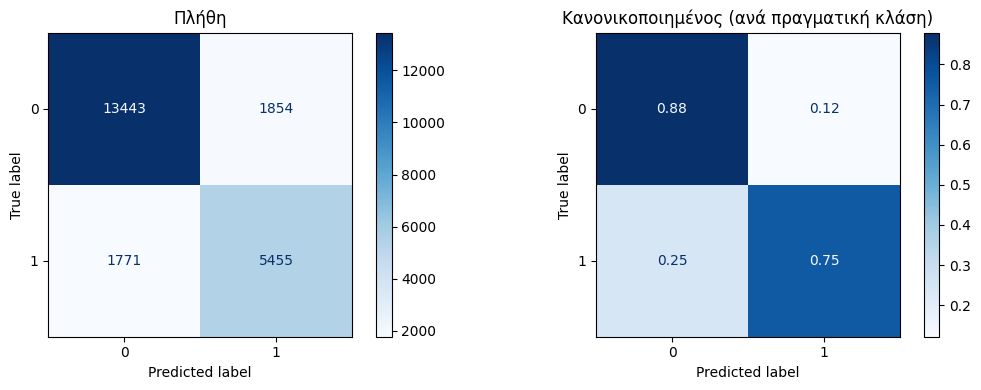

In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_30)
tn, fp, fn, tp = cm.ravel()
print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}')
print(f'Recall (εντοπισμός churners): {tp / (tp + fn):.3f}')
print(f'Specificity (σωστά μη churn): {tn / (tn + fp):.3f}')
print(f'Precision:                    {tp / (tp + fp):.3f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_30, ax=ax[0], cmap='Blues')
ax[0].set_title('Πλήθη')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_30, normalize='true', ax=ax[1],
                                        cmap='Blues', values_format='.2f')
ax[1].set_title('Κανονικοποιημένος (ανά πραγματική κλάση)')
plt.tight_layout()
plt.savefig('xgb_confusion_final.png', dpi=150)
plt.show()

**Συμπέρασμα (confusion matrix):** Στο test set (22.523 γραμμές) το τελικό μοντέλο εντοπίζει σωστά 5.455 από τους 7.226 churners (Recall 0,755) και 13.443 από τους 15.297 πελάτες που έμειναν (Specificity 0,879). Η Precision είναι 0,746: όταν προβλέπει churn, έχει δίκιο στο 75% των περιπτώσεων. Τα λάθη είναι 1.854 ψευδείς συναγερμοί (FP) και 1.771 χαμένοι churners (FN), περίπου ισοζυγισμένα.

#### 11) Feature importance του τελικού μοντέλου
Gain: πόσο βελτιώνει η μεταβλητή τα δέντρα του μοντέλου. Permutation importance (test set): πόσο πέφτει το ROC-AUC όταν ανακατέψουμε τις τιμές της μεταβλητής. Με πορτοκαλί σημειώνονται οι νέες μεταβλητές recency.

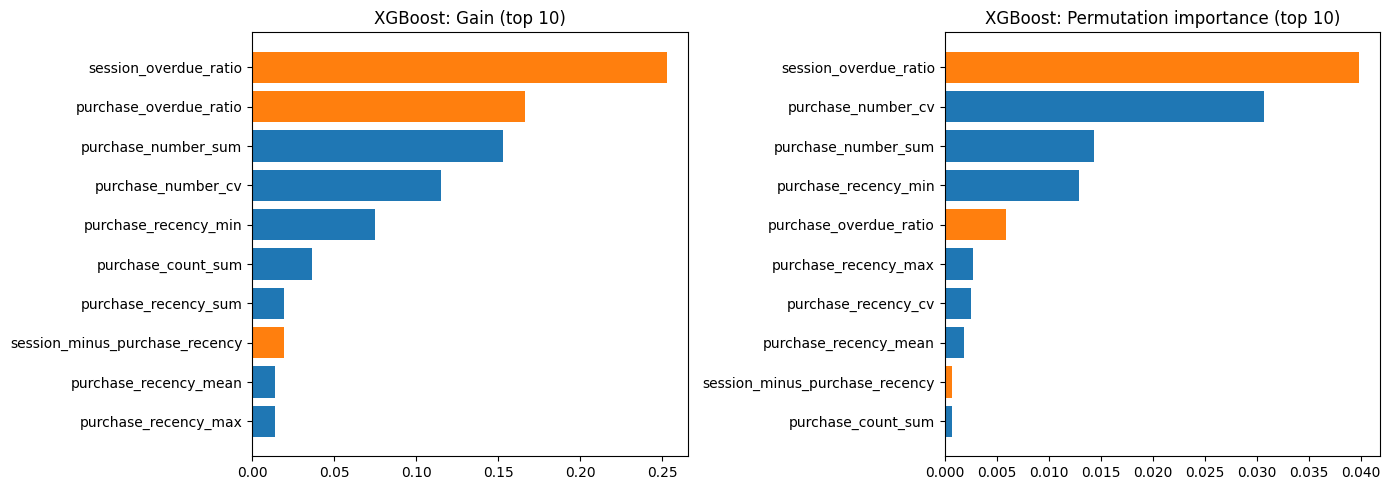

Top 10 κατά permutation importance:
session_overdue_ratio             0.0398
purchase_number_cv                0.0306
purchase_number_sum               0.0144
purchase_recency_min              0.0129
purchase_overdue_ratio            0.0059
purchase_recency_max              0.0027
purchase_recency_cv               0.0026
purchase_recency_mean             0.0019
session_minus_purchase_recency    0.0007
purchase_count_sum                0.0007
dtype: float64


In [25]:
from sklearn.inspection import permutation_importance

gain30 = pd.Series(model_4.feature_importances_, index=final_cols_30)

pi = permutation_importance(model_4, X_test_r[final_cols_30], y_test, scoring='roc_auc',
                            n_repeats=5, random_state=SEED, n_jobs=-1)
perm30 = pd.Series(pi.importances_mean, index=final_cols_30)

pd.DataFrame({'gain': gain30, 'permutation': perm30}) \
  .sort_values('permutation', ascending=False).to_csv('xgb_importance_final.csv')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, s, title in [(ax[0], gain30, 'Gain (top 10)'), (ax[1], perm30, 'Permutation importance (top 10)')]:
    top = s.sort_values().tail(10)
    colors = ['tab:orange' if f in recency_cols else 'tab:blue' for f in top.index]
    a.barh(top.index, top.values, color=colors)
    a.set_title(f'XGBoost: {title}')
plt.tight_layout()
plt.savefig('xgb_importance_final.png', dpi=150)
plt.show()

print('Top 10 κατά permutation importance:')
print(perm30.sort_values(ascending=False).head(10).round(4))

**Συμπέρασμα (feature importance):** Η πιο σημαντική μεταβλητή και στα δύο μέτρα είναι η νέα μεταβλητή session_overdue_ratio (permutation 0,040), και η purchase_overdue_ratio είναι δεύτερη κατά gain. Τα χαρακτηριστικά αγορών (purchase_number_sum, purchase_number_cv) και το recency αγορών (purchase_recency_min) ακολουθούν. Οι δύο μέθοδοι διαφέρουν στη σειρά (π.χ. η purchase_overdue_ratio είναι 2η κατά gain αλλά 5η κατά permutation), κάτι αναμενόμενο όταν οι μεταβλητές είναι συσχετισμένες.
Παρότι το μοντέλο εξαρτάται από λίγες μεταβλητές όπως έχει εκπαιδευτεί, η αφαίρεσή τους και η επανεκπαίδευση μειώνει το CV ROC-AUC το πολύ κατά 0,0008, γιατί άλλες μεταβλητές recency και αγορών αναλαμβάνουν.

In [26]:
print('--- ΣΥΝΟΨΗ ---')
print(f'Τελικό σύνολο: top 30 χαρακτηριστικά (από 55 = 51 + 4 recency)')
print(f'CV ROC-AUC: baseline 0,8990 -> + recency 0,9026 -> + Optuna {study.best_value:.4f} -> top 30 0,9036')
print('Test set:')
print(results_4)
print(f'Confusion matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}')
print('Αρχεία: xgb_best_params.json, xgb_test_results_with_top30.csv, xgb_importance_final.csv,')
print('        xgb_confusion_final.png, xgb_importance_final.png')

--- ΣΥΝΟΨΗ ---
Τελικό σύνολο: top 30 χαρακτηριστικά (από 55 = 51 + 4 recency)
CV ROC-AUC: baseline 0,8990 -> + recency 0,9026 -> + Optuna 0.9035 -> top 30 0,9036
Test set:
                              Accuracy  Precision  Recall  F1-score  ROC-AUC
1. Notebook 1 (51, baseline)    0.8353     0.7353  0.7606    0.7477   0.8927
2. + recency (55, baseline)     0.8391     0.7471  0.7538    0.7504   0.8963
3. + Optuna (55, Optuna)        0.8392     0.7476  0.7533    0.7504   0.8974
4. Top 30 (30, Optuna)          0.8391     0.7463  0.7549    0.7506   0.8971
Confusion matrix: TN=13443, FP=1854, FN=1771, TP=5455
Αρχεία: xgb_best_params.json, xgb_test_results_with_top30.csv, xgb_importance_final.csv,
        xgb_confusion_final.png, xgb_importance_final.png
